In [1]:
import pandas as pd

inputs = pd.read_csv('/Users/mx23826/Documents/ML_winter_school/BoFlex/SDL Case Studies/Inorganic Nanomaterials/Case2_MHP NCs/Dataset/inputs.csv')
outputs = pd.read_csv('/Users/mx23826/Documents/ML_winter_school/BoFlex/SDL Case Studies/Inorganic Nanomaterials/Case2_MHP NCs/Dataset/outputs.csv')

In [3]:
inputs

,QD,ZnI2,ZnBr2,OA,OLA
0,1.000000,0.000000,0.000000,1.000000,0.000000
1,1.000000,1.000000,1.000000,0.000000,1.000000
2,0.500000,0.500000,0.500000,0.500000,0.500000
3,0.500000,0.500000,0.500000,0.500000,0.500000
4,0.500000,0.500000,0.000000,0.500000,0.000000
...,...,...,...,...,...
1294,0.547186,0.637242,0.372737,0.639060,0.963832
1295,0.408661,0.881985,0.044452,0.448528,0.712489
1296,0.463988,0.798886,0.100168,0.606947,0.723723
1297,0.462418,0.860659,0.083278,0.653757,0.896948


In [4]:
from sklearn.decomposition import PCA
from umap import UMAP

# reducer = PCA(n_components=2)
reducer = UMAP(n_components=2, random_state=42)

data = reducer.fit_transform(inputs)

/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state

/var/folders/kq/j4dy9nn54hxb_xchqqyqm7600000gp/T/ipykernel_51400/1323832079.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(data[:, 0], data[:, 1], cmap='viridis')


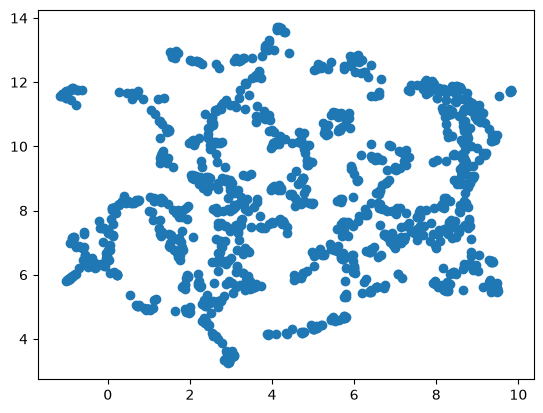

In [5]:
import matplotlib.pyplot as plt

plt.scatter(data[:, 0], data[:, 1], cmap='viridis')

In [6]:
# Data is uncorrelated, so cannot use simple regression. Must use BO!

In [8]:
from sklearn.model_selection import train_test_split

total = pd.concat([inputs, outputs], axis=1)
train, test = train_test_split(total, test_size=0.2, random_state=42)

In [9]:
train

,QD,ZnI2,ZnBr2,OA,OLA,Ep,EFWHM,PLQY
147,0.446810,0.300519,0.597815,0.393754,0.586055,2.214269,0.106498,0.373408
869,0.146161,0.314081,0.013666,0.843279,0.714815,1.910100,0.095872,0.348394
522,0.735857,0.999978,0.000275,0.812628,0.999423,1.887336,0.090339,0.233662
809,0.599699,0.264685,0.444376,0.932006,0.483659,2.072141,0.134358,0.357843
342,0.434425,0.570124,0.410017,0.521934,0.448455,1.935057,0.088719,0.269954
...,...,...,...,...,...,...,...,...
1095,0.418904,0.329553,0.559137,0.571092,0.565124,2.107503,0.115405,0.360011
1130,0.453337,0.615191,0.658363,0.746206,0.352429,1.931790,0.090488,0.306520
1294,0.547186,0.637242,0.372737,0.639060,0.963832,1.942624,0.100364,0.279334
860,0.436622,0.276860,0.935332,0.322730,0.538301,2.293466,0.116718,0.356879


In [7]:
# QD - size of quantum dot?